In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import statsmodels.api as sm
import kagglehub
from  pathlib import Path

### Downloading the data

In [2]:
# Set the path to the file you'd like to load

path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
print("Path to dataset files:", path)

Path to dataset files: /Users/hanane/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3


In [3]:
dataset_dir = Path("/Users/hanane/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3")
csv_path = next(dataset_dir.glob("*.csv"))

In [4]:
df = pd.read_csv(csv_path)
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**1- Crosstab Analysis**

In [5]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [ ]:
crosstab_proportions = crosstab_result.div(crosstab_result.sum(axis=1), axis=0)
crosstab_proportions

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [7]:
crosstab_proportions_sorted = crosstab_proportions.sort_values(by=True, ascending=False)
crosstab_proportions_sorted

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


**2- Statistical tests**

In [8]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)
chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [9]:
cramers_v = association(crosstab_result, method="cramer")
cramers_v

0.1222829439760564

In [10]:
top15_categories = df['category'].value_counts().head(15).index
crosstab_top15 = pd.crosstab(
    df[df['category'].isin(top15_categories)]['category'],
    df[df['category'].isin(top15_categories)]['isBestSeller']
)

In [11]:
crosstab_top15_norm = crosstab_top15.div(crosstab_top15.sum(axis=1), axis=0)

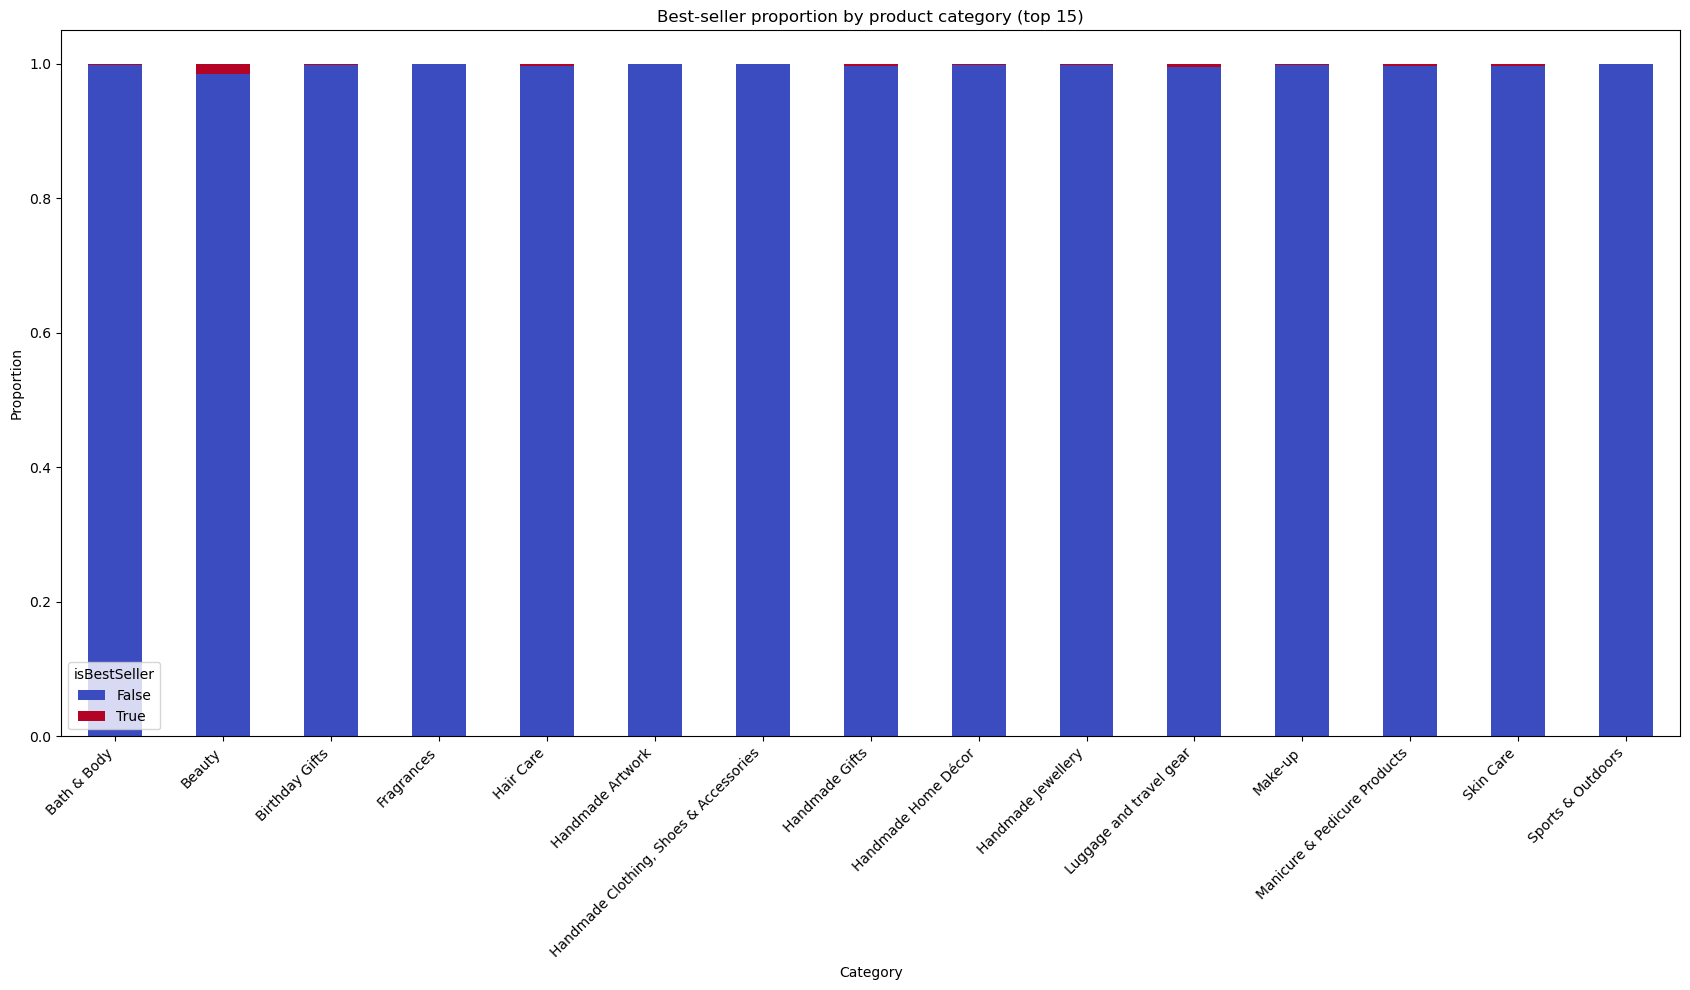

In [17]:
crosstab_top15_norm.plot(kind="bar", stacked=True, colormap="coolwarm", figsize=(17, 10))
plt.title("Best-seller proportion by product category (top 15)")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [19]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR   # anything below this is an outlier
    upper_bound = Q3 + 1.5 * IQR   # anything above this is an outlier
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    return outliers

In [20]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

In [21]:
df_no_outliers = df[(df['price'] >= Q1 - 1.5 * IQR) & (df['price'] <= Q3 + 1.5 * IQR)]

In [22]:
top20_categories = df_no_outliers['category'].value_counts().head(20).index


In [23]:
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

/var/folders/9l/kk5xty3s5gn6t443byvnr8040000gn/T/ipykernel_33803/2659933391.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm")


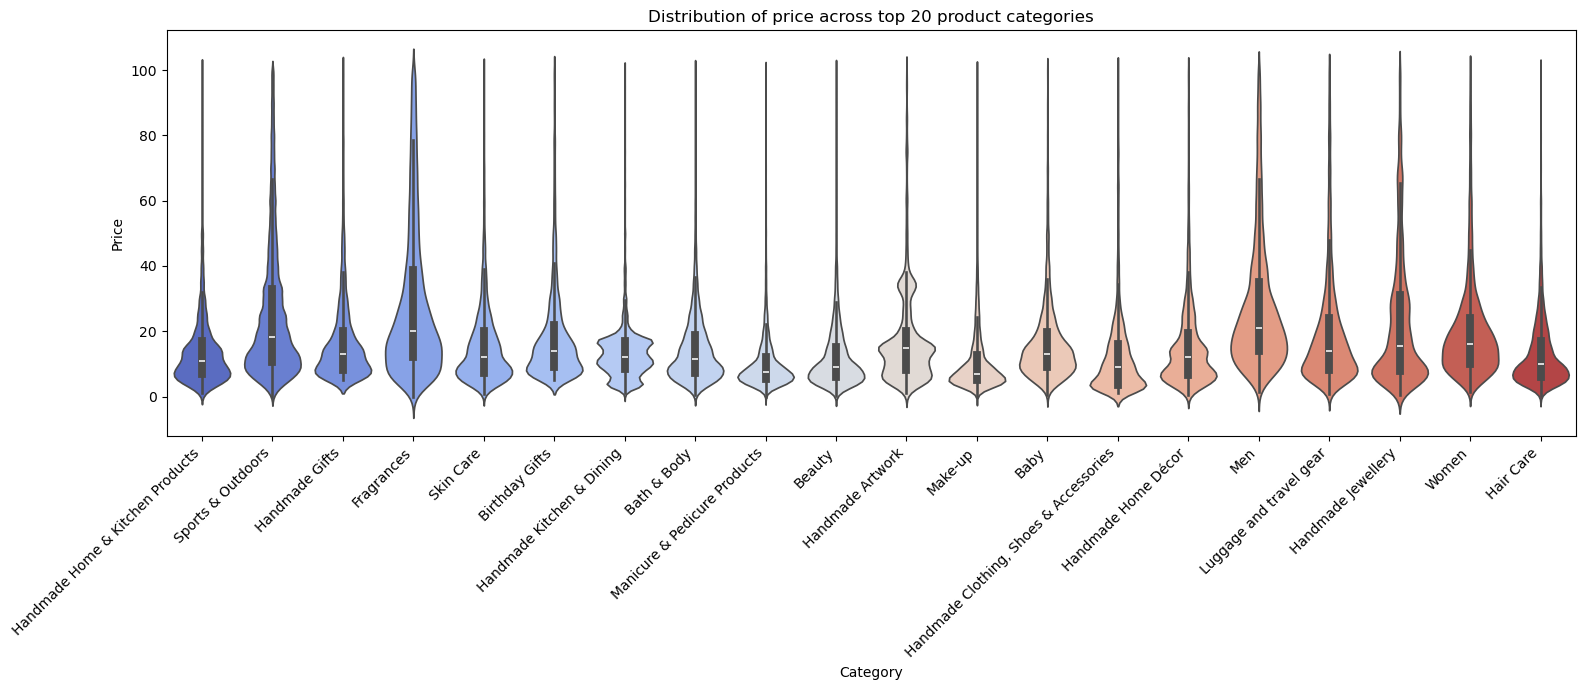

In [25]:
plt.figure(figsize=(16, 7))
sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm")
plt.title("Distribution of price across top 20 product categories")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [27]:
median_price_by_category = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
print(median_price_by_category.head(5))

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64


In [28]:
top10_categories = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

/var/folders/9l/kk5xty3s5gn6t443byvnr8040000gn/T/ipykernel_33803/1572500598.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10, x='category', y='price', palette="coolwarm")


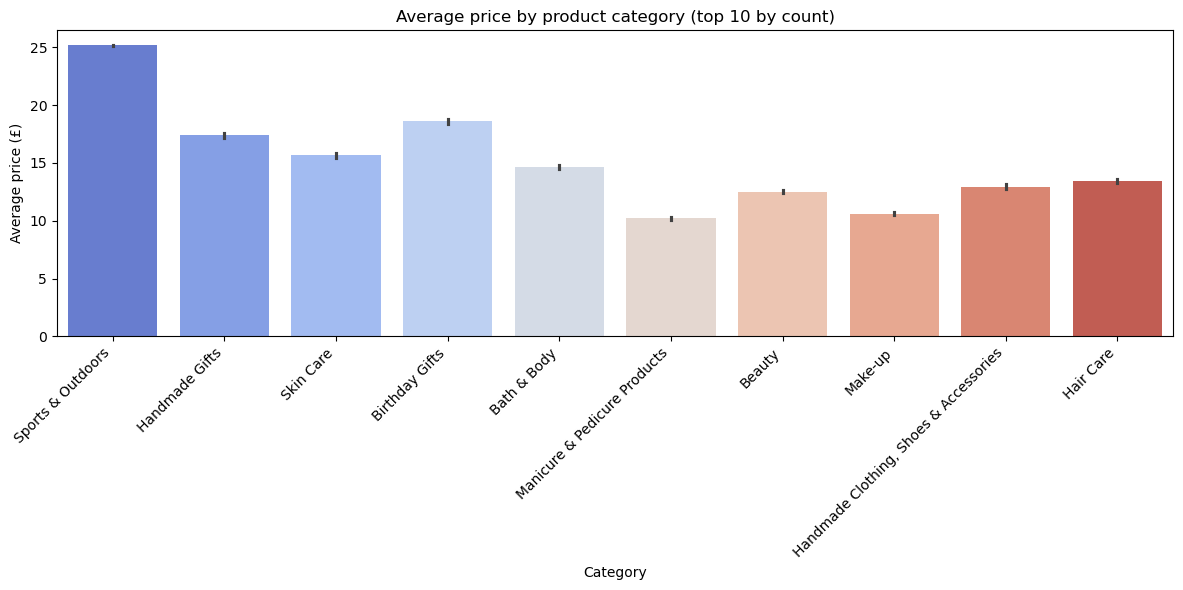

In [29]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df_top10, x='category', y='price', palette="coolwarm")
plt.title("Average price by product category (top 10 by count)")
plt.xlabel("Category")
plt.ylabel("Average price (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [30]:
mean_price_by_category = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
print(mean_price_by_category.head(5))

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64


/var/folders/9l/kk5xty3s5gn6t443byvnr8040000gn/T/ipykernel_33803/1551230988.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")


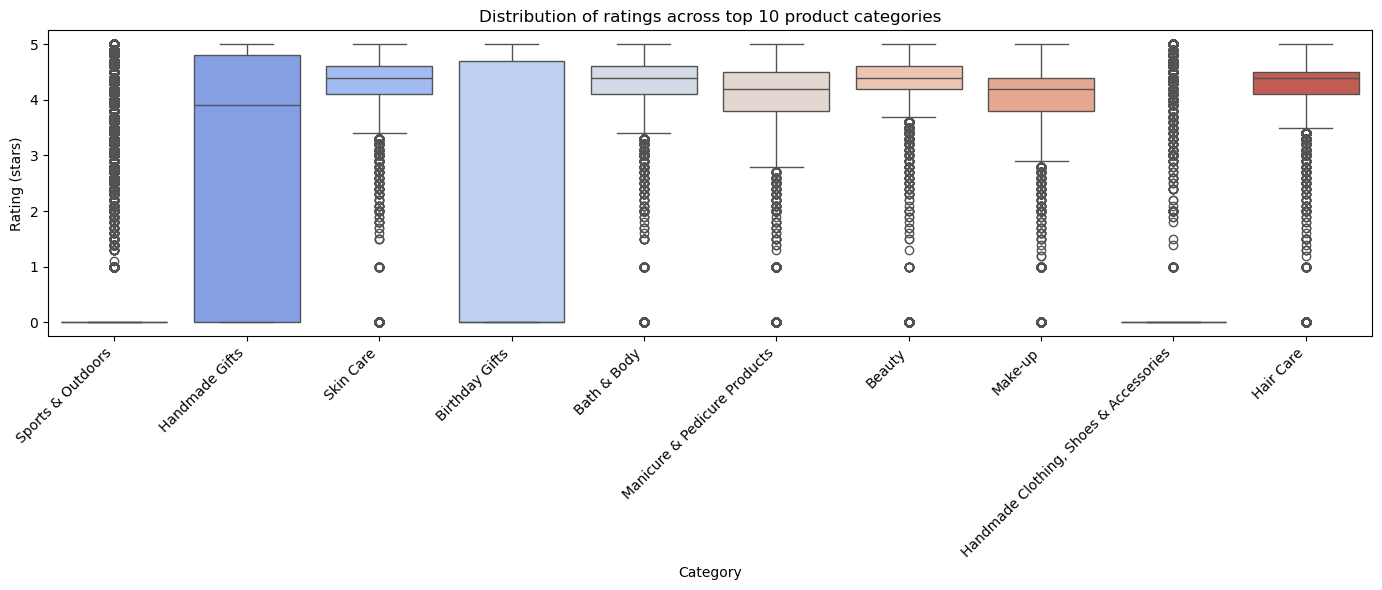

In [31]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")
plt.title("Distribution of ratings across top 10 product categories")
plt.xlabel("Category")
plt.ylabel("Rating (stars)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [33]:
median_rating_by_category = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
print(median_rating_by_category.head(5))

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64


### Part 3: Investigating the Interplay Between Product Prices and Ratings

- Correlation coefficients

In [34]:
pearson_corr = df_no_outliers['price'].corr(df_no_outliers['stars'])

In [35]:
spearman_corr = df_no_outliers['price'].corr(df_no_outliers['stars'], method='spearman')

- 2a. scatter plot - price vs stars

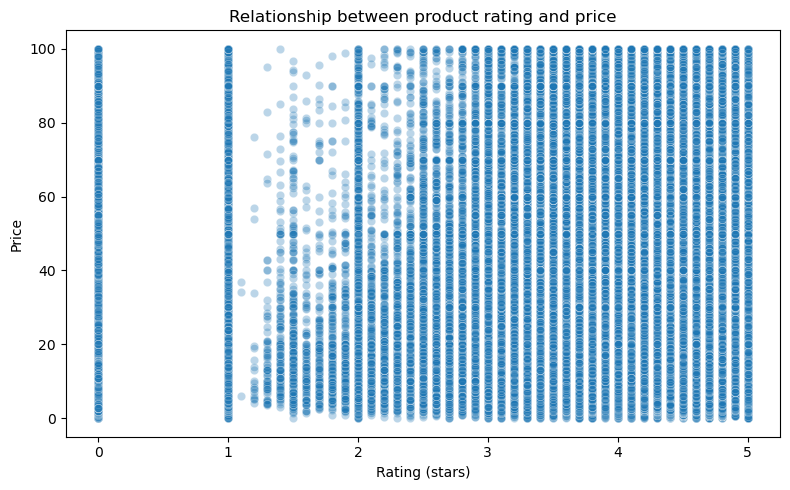

In [37]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_no_outliers, x='stars', y='price', alpha=0.3)
plt.title("Relationship between product rating and price")
plt.xlabel("Rating (stars)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

- 2b - correlation heatmap

In [38]:
df_numerical = df_no_outliers.select_dtypes("number")

In [39]:
correlation_matrix = df_numerical.corr()

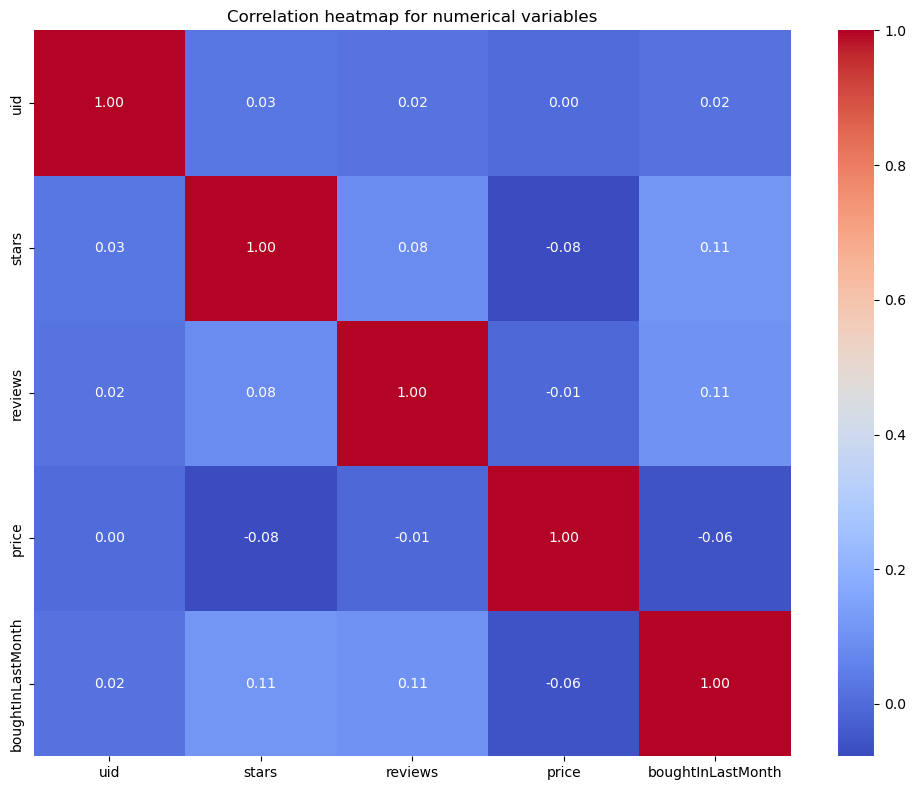

In [40]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap for numerical variables")
plt.tight_layout()
plt.show()

- 2C - QQ plot

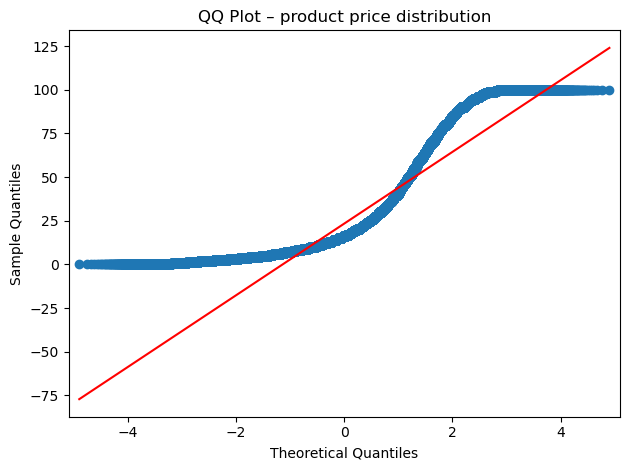

In [41]:
sm.qqplot(df_no_outliers['price'], line='s')
plt.title("QQ Plot – product price distribution")
plt.tight_layout()
plt.show()